In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Every figure is also saved to figures/ so it can be reused in the report and slides
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)


def save_fig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

# Load the results saved by 02_rfm_kmeans.ipynb
DATA_DIR = Path("data")
rfm_df = pd.read_pickle(DATA_DIR / "rfm_df.pkl")
rfm_scaled = pd.read_pickle(DATA_DIR / "rfm_scaled.pkl")
rfm_pca = pd.read_pickle(DATA_DIR / "rfm_pca.pkl")
kmeans_sizes = pd.read_pickle(DATA_DIR / "kmeans_sizes.pkl")
kmeans_medians = pd.read_pickle(DATA_DIR / "kmeans_medians.pkl")
chosen_k = pd.read_pickle(DATA_DIR / "chosen_k.pkl")

# These were imported in 02_rfm_kmeans.ipynb and are used in the cells below
from sklearn.metrics import silhouette_score, adjusted_rand_score

## Train Agglomerative Clustering

We fit agglomerative (hierarchical) clustering on the **same scaled log-RFM features** and the **same number of clusters** (`chosen_k = 4`) so it is comparable with K-means. Ward linkage is used because, like K-means, it groups customers by minimizing within-cluster variance.

In [2]:
# Agglomerative clustering on the same scaled RFM features and same K
from sklearn.cluster import AgglomerativeClustering

agg = AgglomerativeClustering(n_clusters=chosen_k, linkage="ward")
rfm_df["AggCluster"] = agg.fit_predict(rfm_scaled)

print("Agglomerative labels assigned to", len(rfm_df), "customers")
rfm_df.head()

Agglomerative labels assigned to 4338 customers


,CustomerID,Recency,Frequency,Monetary,KMeansCluster,AggCluster
0,12346.0,326,1,77183.60,2,0
1,12347.0,2,7,4310.00,1,1
2,12348.0,75,4,1797.24,2,0
3,12349.0,19,1,1757.55,0,1
4,12350.0,310,1,334.40,3,3


In [3]:
# Agglomerative cluster sizes
agg_sizes = (
    rfm_df["AggCluster"]
    .value_counts()
    .sort_index()
    .rename("Customers")
    .to_frame()
)
agg_sizes["SharePct"] = agg_sizes["Customers"] / agg_sizes["Customers"].sum() * 100
agg_sizes.round(1)

,Customers,SharePct
AggCluster,,
0,1820,42.0
1,1364,31.4
2,242,5.6
3,912,21.0


### Dendrogram

The dendrogram shows the order in which Ward linkage merges groups. The full tree has 4,338 leaves, so we only show the last 30 merges. The dashed line is where the tree is cut to get 4 clusters.

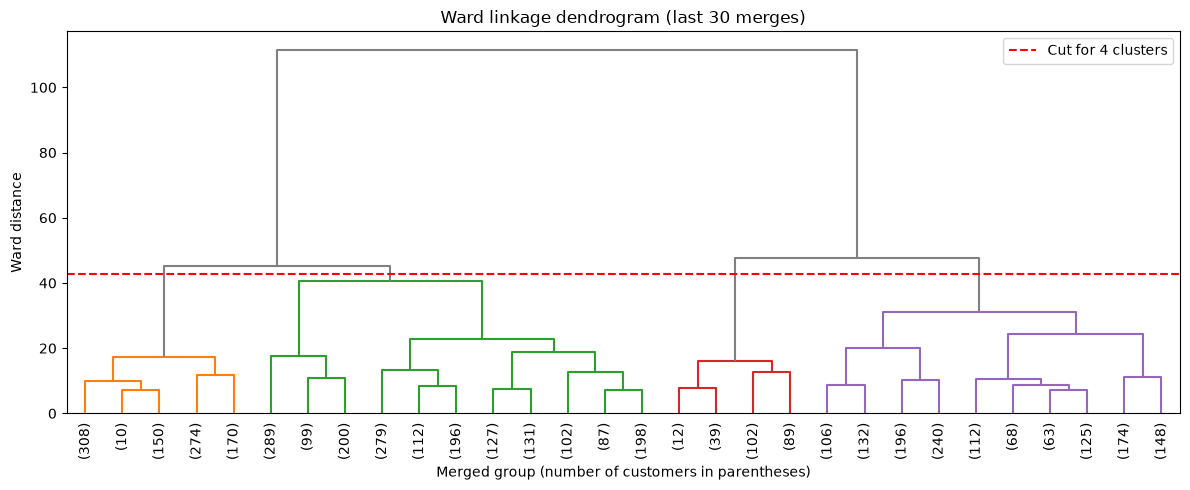

Agreement with AgglomerativeClustering labels (ARI): 1.0
Heights of the last five merges: [ 31.2  40.5  45.2  47.6 111.6]


In [4]:
# Dendrogram of the same Ward hierarchy, showing only the last 30 merges
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage

ward_linkage = linkage(rfm_scaled.values, method="ward")

# Height halfway between the merges that leave 4 clusters and 3 clusters
cut_height = (ward_linkage[-chosen_k, 2] + ward_linkage[-(chosen_k - 1), 2]) / 2

fig, ax = plt.subplots(figsize=(12, 5))
dendrogram(
    ward_linkage,
    truncate_mode="lastp",
    p=30,
    color_threshold=cut_height,
    above_threshold_color="gray",
    show_leaf_counts=True,
    leaf_rotation=90,
    ax=ax,
)
ax.axhline(cut_height, color="red", linestyle="--", label=f"Cut for {chosen_k} clusters")
ax.set(
    title="Ward linkage dendrogram (last 30 merges)",
    xlabel="Merged group (number of customers in parentheses)",
    ylabel="Ward distance",
)
ax.legend()
plt.tight_layout()
save_fig("dendrogram")
plt.show()

# Cutting this tree into 4 clusters reproduces the AgglomerativeClustering labels
tree_labels = fcluster(ward_linkage, t=chosen_k, criterion="maxclust")
print("Agreement with AgglomerativeClustering labels (ARI):", round(adjusted_rand_score(rfm_df["AggCluster"], tree_labels), 3))
print("Heights of the last five merges:", ward_linkage[-5:, 2].round(1))

The last merge is much taller than the rest, so the clearest split is into two groups, which matches K = 2 having the best silhouette score. Below that the merge heights are close together, so the tree does not point to one obvious number of clusters. We cut at 4 to match K-means.

## Compare both clustering methods

Feedback on our abstract suggested checking whether a second clustering method finds the same segments as K-means. Both models use the same scaled features and the same K. We compare silhouette scores, the Adjusted Rand Index, cluster sizes, median RFM values, and a crosstab of the two sets of labels.

In [5]:
agg_labels = rfm_df["AggCluster"]
sil_kmeans = silhouette_score(rfm_scaled, rfm_df["KMeansCluster"])
sil_agg = silhouette_score(rfm_scaled, agg_labels)
ari = adjusted_rand_score(rfm_df["KMeansCluster"], agg_labels)

print(f"K-means silhouette:        {sil_kmeans:.3f}")
print(f"Agglomerative silhouette:  {sil_agg:.3f}")
print(f"Adjusted Rand Index:       {ari:.3f}")

method_comparison = pd.DataFrame(
    {
        "Silhouette": [sil_kmeans, sil_agg],
        "SmallestCluster": [kmeans_sizes["Customers"].min(), agg_sizes["Customers"].min()],
        "LargestCluster": [kmeans_sizes["Customers"].max(), agg_sizes["Customers"].max()],
    },
    index=["K-means", "Agglomerative (Ward)"],
)
method_comparison.round(3)

K-means silhouette:        0.337
Agglomerative silhouette:  0.242
Adjusted Rand Index:       0.248


,Silhouette,SmallestCluster,LargestCluster
K-means,0.337,716,1612
Agglomerative (Ward),0.242,242,1820


In [6]:
size_comparison = pd.concat(
    [kmeans_sizes.add_prefix("KMeans_"), agg_sizes.add_prefix("Agg_")],
    axis=1,
)
size_comparison.round(1)

,KMeans_Customers,KMeans_SharePct,Agg_Customers,Agg_SharePct
0,837,19.3,1820,42.0
1,716,16.5,1364,31.4
2,1173,27.0,242,5.6
3,1612,37.2,912,21.0


In [7]:
agg_medians = (
    rfm_df.groupby("AggCluster")[["Recency", "Frequency", "Monetary"]]
    .median()
    .round(2)
)

print("K-means medians")
display(kmeans_medians)
print("Agglomerative medians")
display(agg_medians)

K-means medians


,Recency,Frequency,Monetary
KMeansCluster,,,
0,17.0,2.0,471.70
1,8.0,10.0,3733.87
2,56.0,4.0,1345.62
3,177.0,1.0,298.26


Agglomerative medians


,Recency,Frequency,Monetary
AggCluster,,,
0,64.0,2.0,529.95
1,17.0,5.0,1720.85
2,7.0,18.0,7507.88
3,245.5,1.0,230.82


In [8]:
# The cluster numbers are arbitrary
# K-Means cluster 0 is not exactly the same as Agglomerative cluster 0
# This will show what K-Means customers will be in what agglomerative cluster.
overlap = pd.crosstab(
    rfm_df["KMeansCluster"], rfm_df["AggCluster"],
    rownames=["KMeans"], colnames=["Agg"],
)
display(overlap)

# Same table as row percentages
display((overlap.div(overlap.sum(axis=1), axis=0) * 100).round(1))

Agg,0,1,2,3
KMeans,,,,
0,523,314,0,0
1,0,474,242,0
2,589,576,0,8
3,708,0,0,904


Agg,0,1,2,3
KMeans,,,,
0,62.5,37.5,0.0,0.0
1,0.0,66.2,33.8,0.0
2,50.2,49.1,0.0,0.7
3,43.9,0.0,0.0,56.1


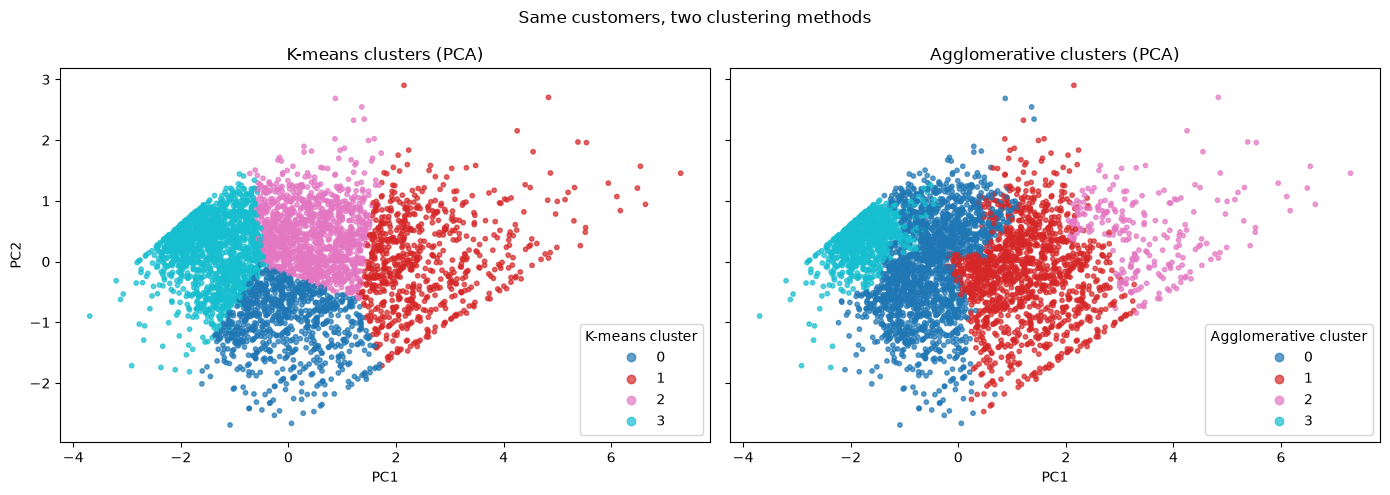

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)

for ax, col, title in zip(
    axes, ["KMeansCluster", "AggCluster"], ["K-means", "Agglomerative"]
):
    scatter = ax.scatter(rfm_pca[:, 0], rfm_pca[:, 1], c=rfm_df[col], cmap="tab10", s=10, alpha=0.7)
    ax.set(title=f"{title} clusters (PCA)", xlabel="PC1")
    ax.legend(*scatter.legend_elements(), title=f"{title} cluster", loc="lower right")
axes[0].set_ylabel("PC2")

# Cluster numbers are arbitrary, so the same color does not mean the same group in both panels
fig.suptitle("Same customers, two clustering methods")
plt.tight_layout()
save_fig("kmeans_vs_agglomerative_pca")
plt.show()

### What the comparison shows

The two methods only partly agree (ARI of 0.25).

- They agree on the extremes. The smallest agglomerative cluster (242 customers, median 18 orders) is completely inside the K-means cluster with the best customers, and almost all of the agglomerative cluster with the longest recency (904 of 912) is inside the K-means cluster of inactive customers.
- They disagree in the middle. Agglomerative puts 1,820 customers into one big cluster that K-means splits across three of its clusters.
- K-means agreed with itself at 0.94 or higher across seeds, so the difference comes from the method and not from randomness.

We think this happens because the customers form a continuum instead of separate clumps, so there is no single correct place to draw the boundaries. Ward linkage also cannot undo a merge once it is made, while K-means keeps reassigning points.

We use K-means for the final segments because it has the higher silhouette score (0.337 vs 0.242) and more even cluster sizes.

## Baseline: traditional RFM quintile scoring

Before clustering, the usual way to segment customers with RFM is to score each customer 1 to 5 on each feature by quintile (Hughes, 1994). We use that as a baseline:

- Recency is reversed, so the most recent 20% of customers score 5.
- Frequency is ranked first, because about a third of customers have exactly one order and identical values cannot be split into quintiles.
- The three scores are kept as cells (for example 5-5-5) or summed into a total from 3 to 15. We cut the total into four tiers (3-5, 6-8, 9-11, 12-15) so the baseline has the same number of groups as K-means.

We score both versions with the same silhouette measure on the same scaled log-RFM features, and compare the tiers with K-means using ARI and a crosstab.

In [10]:
# Classic RFM quintile scores (1 = worst, 5 = best), kept in a separate table so rfm_df is saved unchanged
baseline_df = rfm_df[["CustomerID", "Recency", "Frequency", "Monetary", "KMeansCluster", "AggCluster"]].copy()
baseline_df["R_score"] = pd.qcut(baseline_df["Recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
baseline_df["F_score"] = pd.qcut(baseline_df["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
baseline_df["M_score"] = pd.qcut(baseline_df["Monetary"], 5, labels=[1, 2, 3, 4, 5]).astype(int)

# Version 1: every R-F-M combination is its own cell
rfm_cell = baseline_df[["R_score", "F_score", "M_score"]].astype(str).agg("".join, axis=1)
cell_counts = rfm_cell.value_counts()
print("Occupied RFM cells:", len(cell_counts), "| cells with fewer than 10 customers:", (cell_counts < 10).sum())

# Version 2: sum the scores and cut into four tiers
rfm_score = baseline_df[["R_score", "F_score", "M_score"]].sum(axis=1)
baseline_df["RFMTier"] = pd.cut(
    rfm_score, bins=[2, 5, 8, 11, 15],
    labels=["Low (3-5)", "Mid-low (6-8)", "Mid-high (9-11)", "Top (12-15)"],
)
tier_codes = baseline_df["RFMTier"].cat.codes

baseline_comparison = pd.DataFrame(
    {
        "Groups": [len(cell_counts), 4, chosen_k, chosen_k],
        "Silhouette": [
            silhouette_score(rfm_scaled, rfm_cell),
            silhouette_score(rfm_scaled, tier_codes),
            silhouette_score(rfm_scaled, baseline_df["AggCluster"]),
            silhouette_score(rfm_scaled, baseline_df["KMeansCluster"]),
        ],
        "ARI vs K-means": [
            np.nan,
            adjusted_rand_score(baseline_df["KMeansCluster"], tier_codes),
            adjusted_rand_score(baseline_df["KMeansCluster"], baseline_df["AggCluster"]),
            1.0,
        ],
    },
    index=["RFM quintile cells", "RFM score tiers", "Agglomerative (Ward)", "K-means"],
)
display(baseline_comparison.round(3))

# Size, revenue share, and median RFM of each tier
tier_summary = baseline_df.groupby("RFMTier", observed=True).agg(
    Customers=("CustomerID", "count"),
    Recency=("Recency", "median"),
    Frequency=("Frequency", "median"),
    Monetary=("Monetary", "median"),
    Revenue=("Monetary", "sum"),
)
tier_summary["CustomerPct"] = tier_summary["Customers"] / tier_summary["Customers"].sum() * 100
tier_summary["RevenuePct"] = tier_summary["Revenue"] / tier_summary["Revenue"].sum() * 100
display(tier_summary.drop(columns="Revenue").iloc[::-1].round(1))

# Where the K-means clusters land in the baseline tiers (names match the segments below)
kmeans_names = {0: "Recent low spenders", 1: "Loyal high-value", 2: "Mid-value at risk", 3: "Inactive one-time"}
pd.crosstab(baseline_df["KMeansCluster"].map(kmeans_names), baseline_df["RFMTier"], rownames=["K-means"], colnames=["RFM tier"])

Occupied RFM cells: 118 | cells with fewer than 10 customers: 34


,Groups,Silhouette,ARI vs K-means
RFM quintile cells,118,0.023,NaN
RFM score tiers,4,0.196,0.362
Agglomerative (Ward),4,0.242,0.248
K-means,4,0.337,1.000


,Customers,Recency,Frequency,Monetary,CustomerPct,RevenuePct
RFMTier,,,,,,
Top (12-15),1255,12.0,7.0,2552.2,28.9,76.7
Mid-high (9-11),1022,40.0,3.0,835.4,23.6,13.4
Mid-low (6-8),1178,74.0,1.0,401.0,27.2,7.7
Low (3-5),883,239.0,1.0,200.2,20.4,2.3


RFM tier,Low (3-5),Mid-low (6-8),Mid-high (9-11),Top (12-15)
K-means,,,,
Inactive one-time,882,720,10,0
Loyal high-value,0,0,1,715
Mid-value at risk,0,144,622,407
Recent low spenders,1,314,389,133


### What the baseline shows

- Quintile cells are too fine to use. 118 of the 125 possible cells are occupied, 34 of them by fewer than 10 customers, and the cells barely separate customers (silhouette 0.023).
- Four score tiers are usable, but K-means separates customers better (silhouette 0.337 vs 0.196, and an ARI of 0.36 between the two).
- The top tier holds 715 of the 716 loyal high-value customers, but also 407 mid-value at-risk customers and 133 recent low spenders. Summing the scores lets high Frequency and Monetary make up for poor Recency, so a regular buyer who has gone quiet scores the same as an active one. K-means keeps those customers in their own at-risk segment, which is the group the win-back recommendations target.
- Silhouette is measured in the same space K-means optimizes, so it favours K-means. Who ends up in each group is the stronger evidence.

In [11]:
# Save rfm_df with the AggCluster column for 04_segments_recommendations.ipynb
pd.to_pickle(rfm_df, DATA_DIR / "rfm_df.pkl")